In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

df = pd.read_csv("agricultural_ml_pandas_assignment.csv")

print(df.head())
print(df.tail())
print(df.sample(10, random_state=42))
print("Shape:", df.shape)
print("Size:", df.size)
print("Dimensions:", df.ndim)
print("Columns:", df.columns.tolist())
print("Index:", df.index)
print("Data types:\n", df.dtypes)
df.info()
print(df.describe(include="all"))


         Date      State_Name District_Name  Crop_Year      Season       Crop  \
0  2015-01-23  Madhya Pradesh      Jabalpur       2015      Kharif      Maize   
1  2015-01-06   Uttar Pradesh        Kanpur       2015  Whole Year       Rice   
2  2017-01-03       Karnataka      Belagavi       2017      Kharif     Tomato   
3  2019-12-19  Madhya Pradesh      Jabalpur       2019        Rabi     Pulses   
4  2017-10-02     Maharashtra        Nashik       2017      Kharif  Sugarcane   

   Area_Hectare  Production_Tonnes Rainfall_mm  Temperature_C  Soil_pH  \
0         15.26              42.26       769.9           23.4     6.40   
1         19.18              67.02       856.6            NaN     5.21   
2          5.00              23.43       916.4           28.4     7.26   
3         34.88             113.06      1309.0           26.5     7.37   
4         22.10             104.15       989.3           26.1     7.89   

   Fertilizer_kg_ha  Labor_Days_ha Market_Price_Rs_kg  
0           

In [3]:
print("Missing values:")
print(df.isna().sum())
print(df.isnull().sum())

print("Any missing values:")
print(df.isna().any())

print("Non-missing values:")
print(df.notna().sum())

print("Duplicate rows:", df.duplicated().sum())

# Work on a copy
data = df.copy()

# Convert deliberately corrupted numeric columns
data["Rainfall_mm"] = pd.to_numeric(data["Rainfall_mm"], errors="coerce")
data["Market_Price_Rs_kg"] = pd.to_numeric(
    data["Market_Price_Rs_kg"], errors="coerce"
)

# Convert date
data["Date"] = pd.to_datetime(data["Date"], errors="coerce")

# Remove duplicate rows
data = data.drop_duplicates().reset_index(drop=True)

# Missing-value treatment
numeric_cols = data.select_dtypes(include=np.number).columns
categorical_cols = data.select_dtypes(include="object").columns

for col in numeric_cols:
    data[col] = data[col].fillna(data[col].median())

for col in categorical_cols:
    if data[col].isna().any():
        data[col] = data[col].fillna(data[col].mode()[0])

print(data.isnull().sum())
    

Missing values:
Date                   0
State_Name             0
District_Name         15
Crop_Year              0
Season                 0
Crop                   0
Area_Hectare           0
Production_Tonnes      0
Rainfall_mm           46
Temperature_C         35
Soil_pH               30
Fertilizer_kg_ha      40
Labor_Days_ha          0
Market_Price_Rs_kg    25
dtype: int64
Date                   0
State_Name             0
District_Name         15
Crop_Year              0
Season                 0
Crop                   0
Area_Hectare           0
Production_Tonnes      0
Rainfall_mm           46
Temperature_C         35
Soil_pH               30
Fertilizer_kg_ha      40
Labor_Days_ha          0
Market_Price_Rs_kg    25
dtype: int64
Any missing values:
Date                  False
State_Name            False
District_Name          True
Crop_Year             False
Season                False
Crop                  False
Area_Hectare          False
Production_Tonnes     False
Rainfall_mm   

C:\Users\hp\AppData\Local\Temp\ipykernel_31868\1675544183.py:30: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_cols = data.select_dtypes(include="object").columns


In [4]:
print(data.dtypes)

# astype()
data["Crop_Year"] = data["Crop_Year"].astype(int)

# Selection
print(data["Crop"])
print(data[["Crop", "Production_Tonnes"]])

# loc
print(data.loc[0:4, ["Crop", "Production_Tonnes"]])

# iloc
print(data.iloc[0:5, 0:5])

# Boolean filtering
high_production = data[data["Production_Tonnes"] > data["Production_Tonnes"].mean()]
large_farms = data[data["Area_Hectare"] > 50]

# query()
selected = data.query(
    "Area_Hectare > 20 and Rainfall_mm > 1000 and Temperature_C < 30"
)

# Sorting
highest_production = data.sort_values(
    "Production_Tonnes", ascending=False
)
lowest_area = data.sort_values("Area_Hectare")
sorted_multi = data.sort_values(
    ["Crop", "Production_Tonnes"],
    ascending=[True, False]
)
data = data.sort_index()

print(high_production.head())
print(large_farms.head())
print(selected.head())



Date                  datetime64[us]
State_Name                       str
District_Name                    str
Crop_Year                      int64
Season                           str
Crop                             str
Area_Hectare                 float64
Production_Tonnes            float64
Rainfall_mm                  float64
Temperature_C                float64
Soil_pH                      float64
Fertilizer_kg_ha             float64
Labor_Days_ha                float64
Market_Price_Rs_kg           float64
dtype: object
0           Maize
1            Rice
2          Tomato
3          Pulses
4       Sugarcane
          ...    
2995       Potato
2996       Tomato
2997       Cotton
2998       Tomato
2999       Potato
Name: Crop, Length: 3000, dtype: str
           Crop  Production_Tonnes
0         Maize              42.26
1          Rice              67.02
2        Tomato              23.43
3        Pulses             113.06
4     Sugarcane             104.15
...         ...        

In [5]:
print(data.dtypes)

# astype()
data["Crop_Year"] = data["Crop_Year"].astype(int)

# Selection
print(data["Crop"])
print(data[["Crop", "Production_Tonnes"]])

# loc
print(data.loc[0:4, ["Crop", "Production_Tonnes"]])

# iloc
print(data.iloc[0:5, 0:5])

# Boolean filtering
high_production = data[data["Production_Tonnes"] > data["Production_Tonnes"].mean()]
large_farms = data[data["Area_Hectare"] > 50]

# query()
selected = data.query(
    "Area_Hectare > 20 and Rainfall_mm > 1000 and Temperature_C < 30"
)

# Sorting
highest_production = data.sort_values(
    "Production_Tonnes", ascending=False
)
lowest_area = data.sort_values("Area_Hectare")
sorted_multi = data.sort_values(
    ["Crop", "Production_Tonnes"],
    ascending=[True, False]
)
data = data.sort_index()

print(high_production.head())
print(large_farms.head())
print(selected.head())


Date                  datetime64[us]
State_Name                       str
District_Name                    str
Crop_Year                      int64
Season                           str
Crop                             str
Area_Hectare                 float64
Production_Tonnes            float64
Rainfall_mm                  float64
Temperature_C                float64
Soil_pH                      float64
Fertilizer_kg_ha             float64
Labor_Days_ha                float64
Market_Price_Rs_kg           float64
dtype: object
0           Maize
1            Rice
2          Tomato
3          Pulses
4       Sugarcane
          ...    
2995       Potato
2996       Tomato
2997       Cotton
2998       Tomato
2999       Potato
Name: Crop, Length: 3000, dtype: str
           Crop  Production_Tonnes
0         Maize              42.26
1          Rice              67.02
2        Tomato              23.43
3        Pulses             113.06
4     Sugarcane             104.15
...         ...        

In [6]:
# Yield
data["Yield_Tonnes_Ha"] = (
    data["Production_Tonnes"] / data["Area_Hectare"]
)

data["Yield_Tonnes_Ha"] = (
    data["Yield_Tonnes_Ha"]
    .replace([np.inf, -np.inf], np.nan)
)

data["Yield_Tonnes_Ha"] = data["Yield_Tonnes_Ha"].fillna(
    data["Yield_Tonnes_Ha"].median()
)

# Production efficiency
data["Production_Efficiency"] = (
    data["Production_Tonnes"] / data["Area_Hectare"]
)

# Date features
data["Year"] = data["Date"].dt.year
data["Month"] = data["Date"].dt.month
data["Quarter"] = data["Date"].dt.quarter
data["Day"] = data["Date"].dt.day
data["Day_of_Week"] = data["Date"].dt.dayofweek

# cut()
data["Production_Category"] = pd.cut(
    data["Production_Tonnes"],
    bins=[-np.inf, 50, 150, np.inf],
    labels=["Low", "Medium", "High"]
)

# qcut()
data["Production_Quartile"] = pd.qcut(
    data["Production_Tonnes"],
    q=4,
    labels=["Q1", "Q2", "Q3", "Q4"],
    duplicates="drop"
)

print(data.head())


        Date      State_Name District_Name  Crop_Year      Season       Crop  \
0 2015-01-23  Madhya Pradesh      Jabalpur       2015      Kharif      Maize   
1 2015-01-06   Uttar Pradesh        Kanpur       2015  Whole Year       Rice   
2 2017-01-03       Karnataka      Belagavi       2017      Kharif     Tomato   
3 2019-12-19  Madhya Pradesh      Jabalpur       2019        Rabi     Pulses   
4 2017-10-02     Maharashtra        Nashik       2017      Kharif  Sugarcane   

   Area_Hectare  Production_Tonnes  Rainfall_mm  Temperature_C  ...  \
0         15.26              42.26        769.9           23.4  ...   
1         19.18              67.02        856.6           27.1  ...   
2          5.00              23.43        916.4           28.4  ...   
3         34.88             113.06       1309.0           26.5  ...   
4         22.10             104.15        989.3           26.1  ...   

   Market_Price_Rs_kg  Yield_Tonnes_Ha  Production_Efficiency  Year  Month  \
0             

In [9]:
# apply()
data["Yield_Level"] = data["Yield_Tonnes_Ha"].apply(
    lambda x: "High Yield" if x >= data["Yield_Tonnes_Ha"].median()
    else "Low Yield"
)

# map()
season_map = {
    "Kharif": 1,
    "Rabi": 2,
    "Summer": 3,
    "Whole_Year": 4
}
data["Season_Code"] = data["Season"].map(season_map)

# assign()
data = data.assign(
    Rainfall_Temperature_Index=
    data["Rainfall_mm"] / (data["Temperature_C"] + 1)
)

# insert()
if "Area_per_Labor_Day" not in data.columns:
    data.insert(
        len(data.columns),
        "Area_per_Labor_Day",
        data["Area_Hectare"] / (data["Labor_Days_ha"] + 1)
    )


In [10]:
# Inspect categories
print(data["Crop"].unique())
print(data["Crop"].nunique())
print(data["Crop"].value_counts())
print(data["Crop"].value_counts(normalize=True))

# Factorize
data["Crop_Code"], crop_labels = pd.factorize(data["Crop"])

# One-hot encoding
encoded = pd.get_dummies(
    data,
    columns=["Season"],
    dtype=int
)

print(encoded.head())


<ArrowStringArray>
['Maize', 'Rice', 'Tomato', 'Pulses', 'Sugarcane', 'Cotton', 'Wheat',
 'Potato']
Length: 8, dtype: str
8
Crop
Sugarcane    395
Cotton       388
Maize        386
Pulses       382
Tomato       373
Potato       371
Wheat        359
Rice         346
Name: count, dtype: int64
Crop
Sugarcane    0.131667
Cotton       0.129333
Maize        0.128667
Pulses       0.127333
Tomato       0.124333
Potato       0.123667
Wheat        0.119667
Rice         0.115333
Name: proportion, dtype: float64
        Date      State_Name District_Name  Crop_Year       Crop  \
0 2015-01-23  Madhya Pradesh      Jabalpur       2015      Maize   
1 2015-01-06   Uttar Pradesh        Kanpur       2015       Rice   
2 2017-01-03       Karnataka      Belagavi       2017     Tomato   
3 2019-12-19  Madhya Pradesh      Jabalpur       2019     Pulses   
4 2017-10-02     Maharashtra        Nashik       2017  Sugarcane   

   Area_Hectare  Production_Tonnes  Rainfall_mm  Temperature_C  Soil_pH  ...  \
0     

In [11]:
numeric_analysis = data.select_dtypes(include=np.number)

print("Count:\n", numeric_analysis.count())
print("Sum:\n", numeric_analysis.sum())
print("Mean:\n", numeric_analysis.mean())
print("Median:\n", numeric_analysis.median())
print("Mode:\n", numeric_analysis.mode().iloc[0])
print("Minimum:\n", numeric_analysis.min())
print("Maximum:\n", numeric_analysis.max())
print("Standard deviation:\n", numeric_analysis.std())
print("Variance:\n", numeric_analysis.var())
print("Quantiles:\n", numeric_analysis.quantile([0.25, 0.50, 0.75]))
print("Skewness:\n", numeric_analysis.skew())
print("Kurtosis:\n", numeric_analysis.kurt())


Count:
 Crop_Year                     3000
Area_Hectare                  3000
Production_Tonnes             3000
Rainfall_mm                   3000
Temperature_C                 3000
Soil_pH                       3000
Fertilizer_kg_ha              3000
Labor_Days_ha                 3000
Market_Price_Rs_kg            3000
Yield_Tonnes_Ha               3000
Production_Efficiency         3000
Year                          3000
Month                         3000
Quarter                       3000
Day                           3000
Day_of_Week                   3000
Season_Code                   2293
Rainfall_Temperature_Index    3000
Area_per_Labor_Day            3000
Crop_Code                     3000
dtype: int64
Sum:
 Crop_Year                     6.060034e+06
Area_Hectare                  1.092192e+05
Production_Tonnes             3.846974e+05
Rainfall_mm                   3.139468e+06
Temperature_C                 8.131630e+04
Soil_pH                       1.984908e+04
Fertilizer_kg_h

In [12]:
print(
    data.groupby("Crop")["Production_Tonnes"].mean()
)

print(
    data.groupby("State_Name")["Production_Tonnes"].sum()
)

print(
    data.groupby("Season")["Yield_Tonnes_Ha"].mean()
)

print(
    data.groupby("Crop")["Market_Price_Rs_kg"].mean()
)

print(
    data.groupby("State_Name")["Rainfall_mm"].mean()
)

crop_statistics = data.groupby("Crop")["Production_Tonnes"].agg(
    ["count", "mean", "min", "max", "std"]
)
print(crop_statistics)

# transform(): crop-level mean production for every row
data["Crop_Average_Production"] = (
    data.groupby("Crop")["Production_Tonnes"]
    .transform("mean")
)

# filter(): retain crops with enough observations
filtered_crops = data.groupby("Crop").filter(
    lambda g: len(g) >= 300
)

print(filtered_crops["Crop"].value_counts())


Crop
Cotton       106.373376
Maize        120.574663
Potato       145.749811
Pulses        92.560890
Rice         131.530434
Sugarcane    158.434810
Tomato       138.067534
Wheat        133.316880
Name: Production_Tonnes, dtype: float64
State_Name
Bihar             47614.01
Karnataka         48783.97
Madhya Pradesh    48357.01
Maharashtra       47912.40
Punjab            50550.51
Tamil Nadu        46401.39
Uttar Pradesh     44005.49
West Bengal       51072.58
Name: Production_Tonnes, dtype: float64
Season
Kharif        3.522914
Rabi          3.479515
Summer        3.537331
Whole Year    3.476642
Name: Yield_Tonnes_Ha, dtype: float64
Crop
Cotton       34.262964
Maize        34.419223
Potato       34.915310
Pulses       34.587173
Rice         34.678382
Sugarcane    34.749291
Tomato       34.821769
Wheat        35.300028
Name: Market_Price_Rs_kg, dtype: float64
State_Name
Bihar             1030.270833
Karnataka         1051.852850
Madhya Pradesh    1052.346739
Maharashtra       1067.48154

In [13]:
numeric = data.select_dtypes(include=np.number)

correlation = numeric.corr()
covariance = numeric.cov()

print("Correlation:")
print(correlation)

print("Covariance:")
print(covariance)

print(
    correlation["Yield_Tonnes_Ha"]
    .sort_values(ascending=False)
)


Correlation:
                            Crop_Year  Area_Hectare  Production_Tonnes  \
Crop_Year                    1.000000      0.018543           0.018253   
Area_Hectare                 0.018543      1.000000           0.939685   
Production_Tonnes            0.018253      0.939685           1.000000   
Rainfall_mm                 -0.018790      0.007141           0.058848   
Temperature_C               -0.006938      0.036343           0.030500   
Soil_pH                      0.016185      0.016315           0.005008   
Fertilizer_kg_ha             0.035692      0.017623           0.080489   
Labor_Days_ha                0.023962      0.004689           0.030656   
Market_Price_Rs_kg           0.014170     -0.021895           0.001795   
Yield_Tonnes_Ha             -0.009016      0.023815           0.279492   
Production_Efficiency       -0.009016      0.023815           0.279492   
Year                         1.000000      0.018543           0.018253   
Month                    

In [14]:
left = data[
    ["Crop", "State_Name", "Area_Hectare", "Production_Tonnes"]
].copy()

right = data[
    ["Crop", "Rainfall_mm", "Temperature_C", "Soil_pH"]
].copy()

# Use a unique key for a clean demonstration
left = left.reset_index(names="Record_ID")
right = right.reset_index(names="Record_ID")

merged = pd.merge(
    left,
    right,
    on="Record_ID",
    how="inner",
    suffixes=("_left", "_right")
)

# concat()
part1 = data.iloc[:100].copy()
part2 = data.iloc[100:200].copy()
concatenated = pd.concat([part1, part2], axis=0)

# join()
left_indexed = left.set_index("Record_ID")
right_indexed = right.set_index("Record_ID")
joined = left_indexed.join(
    right_indexed[["Rainfall_mm", "Temperature_C", "Soil_pH"]],
    how="left"
)

print(merged.head())
print(concatenated.shape)
print(joined.head())


   Record_ID  Crop_left      State_Name  Area_Hectare  Production_Tonnes  \
0          0      Maize  Madhya Pradesh         15.26              42.26   
1          1       Rice   Uttar Pradesh         19.18              67.02   
2          2     Tomato       Karnataka          5.00              23.43   
3          3     Pulses  Madhya Pradesh         34.88             113.06   
4          4  Sugarcane     Maharashtra         22.10             104.15   

  Crop_right  Rainfall_mm  Temperature_C  Soil_pH  
0      Maize        769.9           23.4     6.40  
1       Rice        856.6           27.1     5.21  
2     Tomato        916.4           28.4     7.26  
3     Pulses       1309.0           26.5     7.37  
4  Sugarcane        989.3           26.1     7.89  
(200, 29)
                Crop      State_Name  Area_Hectare  Production_Tonnes  \
Record_ID                                                               
0              Maize  Madhya Pradesh         15.26              42.26   
1 

In [15]:
# pivot()
pivot_df = data.pivot_table(
    index="Crop",
    columns="Crop_Year",
    values="Production_Tonnes",
    aggfunc="sum",
    fill_value=0
)

print(pivot_df)

# melt()
long_df = pivot_df.reset_index().melt(
    id_vars="Crop",
    var_name="Crop_Year",
    value_name="Production_Tonnes"
)

# stack()
stacked = pivot_df.stack()

# unstack()
unstacked = stacked.unstack()

# explode()
example = pd.DataFrame({
    "Crop": ["Rice", "Wheat"],
    "Markets": [["Market_A", "Market_B"], ["Market_C", "Market_D"]]
})
exploded = example.explode("Markets")

print(long_df.head())
print(exploded)


Crop_Year     2015     2016     2017     2018     2019     2020     2021  \
Crop                                                                       
Cotton     5458.00  4772.04  2668.79  3821.34  2611.04  3034.79  4173.26   
Maize      3760.80  3674.46  3457.54  5902.69  3032.96  3078.66  4285.58   
Potato     5630.88  4845.94  4919.11  3774.72  4612.85  5272.61  3510.99   
Pulses     4212.60  2326.90  3614.29  3022.80  2870.61  3636.08  2899.76   
Rice       3065.77  4566.41  4256.99  5823.06  2433.84  3905.37  5142.63   
Sugarcane  5078.68  4328.24  6851.58  3717.72  4592.98  8643.85  5151.38   
Tomato     5716.88  5303.11  5180.25  4068.00  4411.87  4857.90  4650.17   
Wheat      4637.97  4415.09  4381.19  4466.88  2433.08  2894.11  4682.78   

Crop_Year     2022     2023     2024     2025  
Crop                                           
Cotton     2105.77  3712.77  4523.76  4391.31  
Maize      4827.46  5373.49  4979.18  4169.00  
Potato     4412.30  5401.12  6055.77  5636.89  

In [16]:
indexed = data.set_index("Crop")

restored = indexed.reset_index()

# reindex()
first_columns = list(data.columns[:8])
reindexed = data.reindex(columns=first_columns)

# Sampling
sample_100 = data.sample(n=100, random_state=42)
sample_20_percent = data.sample(frac=0.20, random_state=42)

shuffled = data.sample(
    frac=1,
    random_state=42
).reset_index(drop=True)

print(sample_100.shape)
print(sample_20_percent.shape)
print(shuffled.head())



(100, 29)
(600, 29)
        Date      State_Name District_Name  Crop_Year      Season       Crop  \
0 2016-06-21       Karnataka        Mandya       2016  Whole Year     Potato   
1 2015-08-11     Maharashtra      Kolhapur       2015  Whole Year  Sugarcane   
2 2017-02-18  Madhya Pradesh        Bhopal       2017        Rabi     Cotton   
3 2020-10-10     West Bengal   Murshidabad       2020        Rabi       Rice   
4 2017-09-07  Madhya Pradesh        Indore       2017      Kharif       Rice   

   Area_Hectare  Production_Tonnes  Rainfall_mm  Temperature_C  ...  Day  \
0         20.09              82.68       1016.3           25.8  ...   21   
1         11.90              44.26        772.4           27.1  ...   11   
2         25.41              73.24        571.4           31.1  ...   18   
3         63.15             240.00       1265.2           26.4  ...   10   
4         10.93              30.52        250.0           27.0  ...    7   

   Day_of_Week  Production_Category  Produ

In [17]:
ts = data.sort_values("Date").copy()

# Lag
ts["Previous_Production"] = ts["Production_Tonnes"].shift(1)

# Difference
ts["Production_Change"] = ts["Production_Tonnes"].diff()

# Percentage change
ts["Production_Growth"] = ts["Production_Tonnes"].pct_change() * 100

# Rolling average
ts["Production_MA_7"] = (
    ts["Production_Tonnes"]
    .rolling(window=7, min_periods=1)
    .mean()
)

# Resample by year
annual = (
    ts.set_index("Date")
      .resample("YS")["Production_Tonnes"]
      .sum()
)

print(ts.head(10))
print(annual)


           Date      State_Name District_Name  Crop_Year      Season  \
2470 2015-01-03   Uttar Pradesh       Lucknow       2015  Whole Year   
2032 2015-01-03  Madhya Pradesh      Jabalpur       2015        Rabi   
1802 2015-01-04     Maharashtra        Nagpur       2015      Summer   
2635 2015-01-05      Tamil Nadu       Madurai       2015      Summer   
1    2015-01-06   Uttar Pradesh        Kanpur       2015  Whole Year   
2228 2015-01-06     West Bengal       Burdwan       2015      Summer   
1666 2015-01-06           Bihar          Gaya       2015      Kharif   
1772 2015-01-07     West Bengal         Nadia       2015        Rabi   
61   2015-01-08  Madhya Pradesh        Bhopal       2015  Whole Year   
768  2015-01-10   Uttar Pradesh          Agra       2015  Whole Year   

           Crop  Area_Hectare  Production_Tonnes  Rainfall_mm  Temperature_C  \
2470     Pulses        101.72             251.78       1320.9           31.5   
2032     Cotton        142.70             444.0

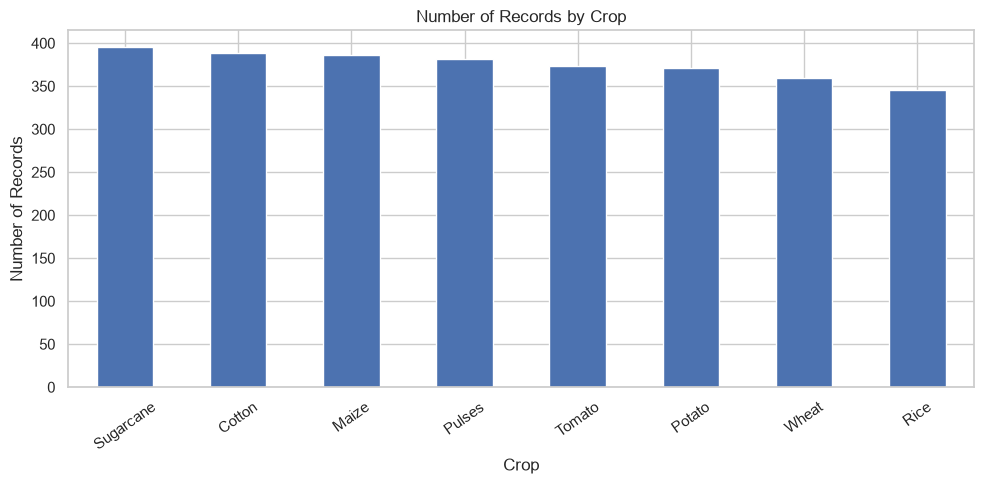

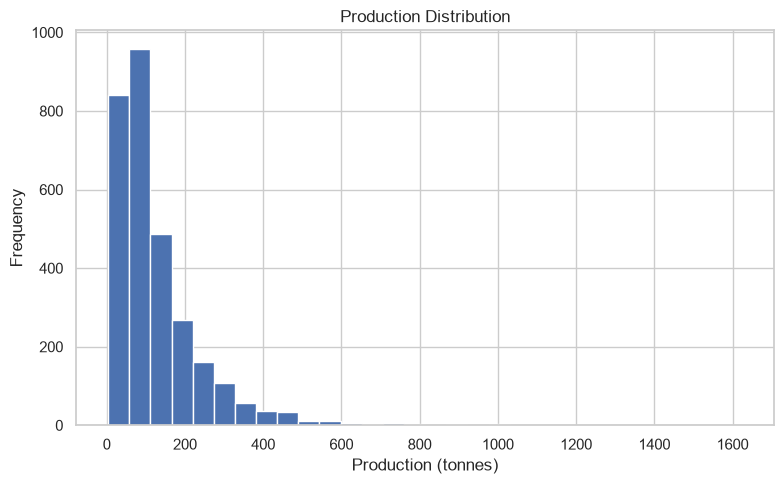

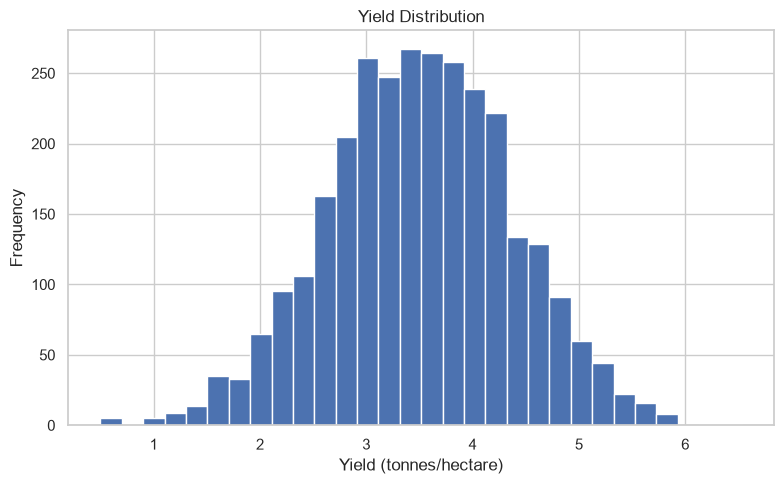

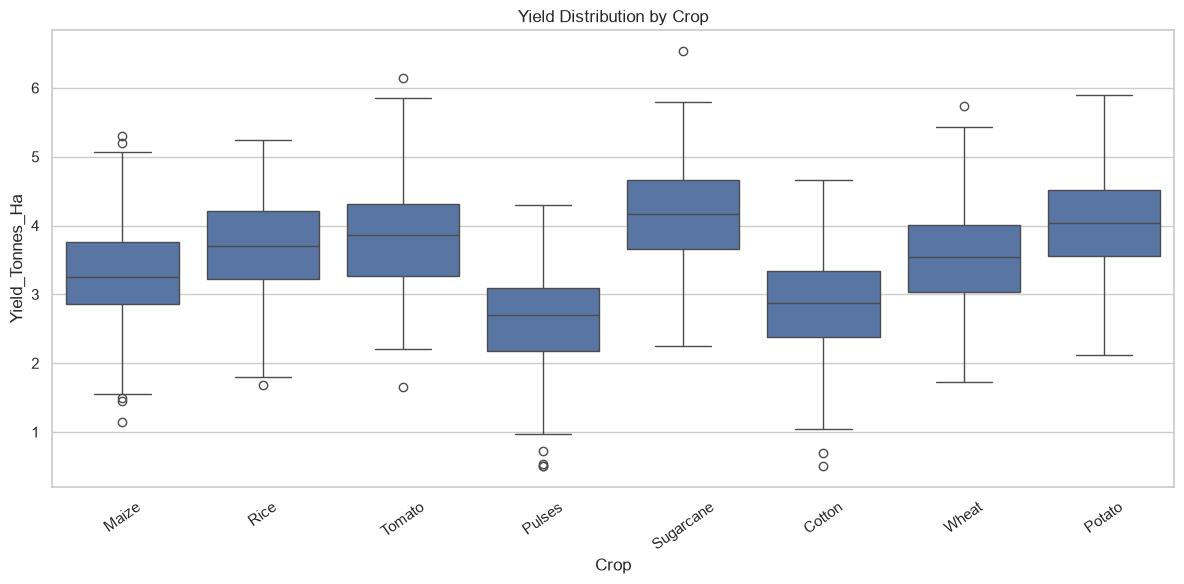

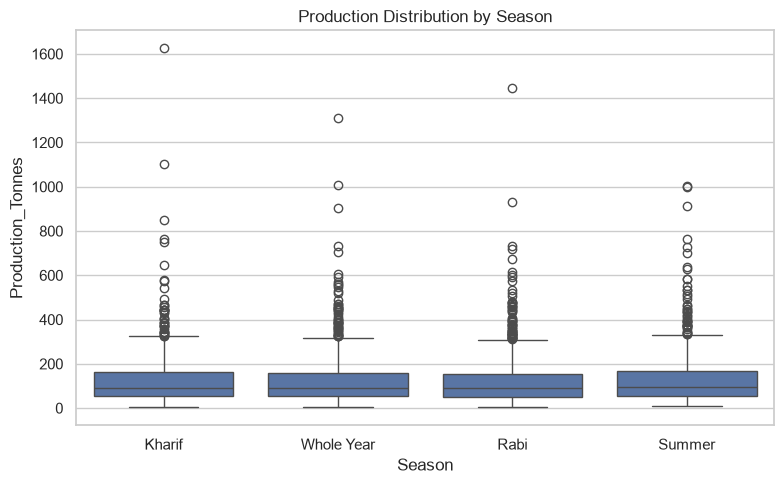

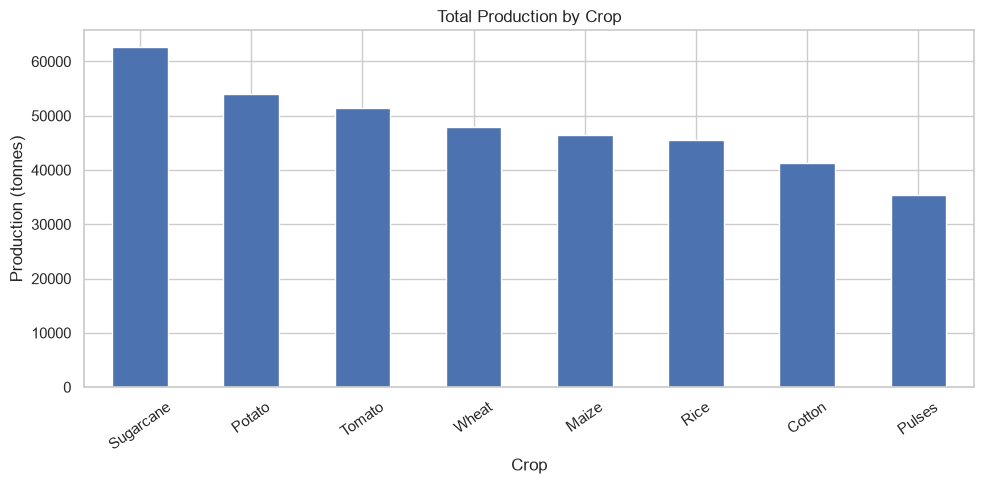

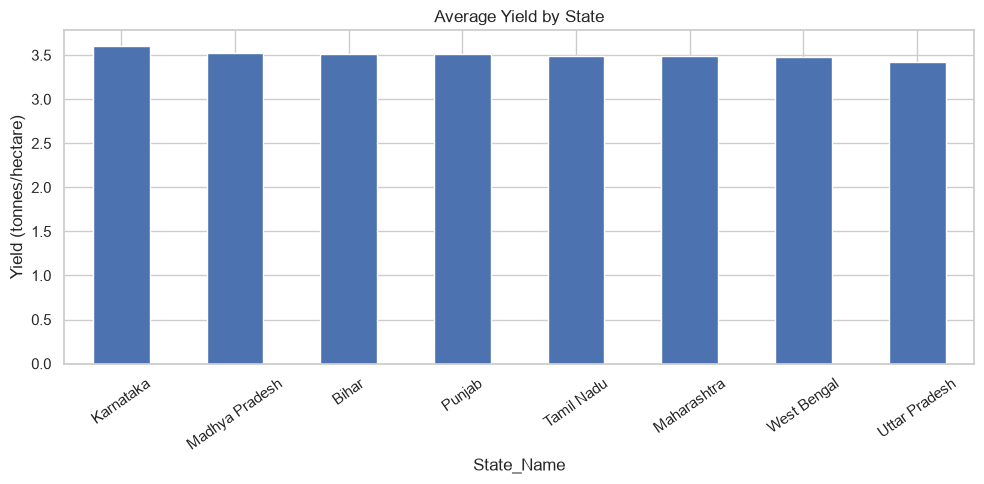

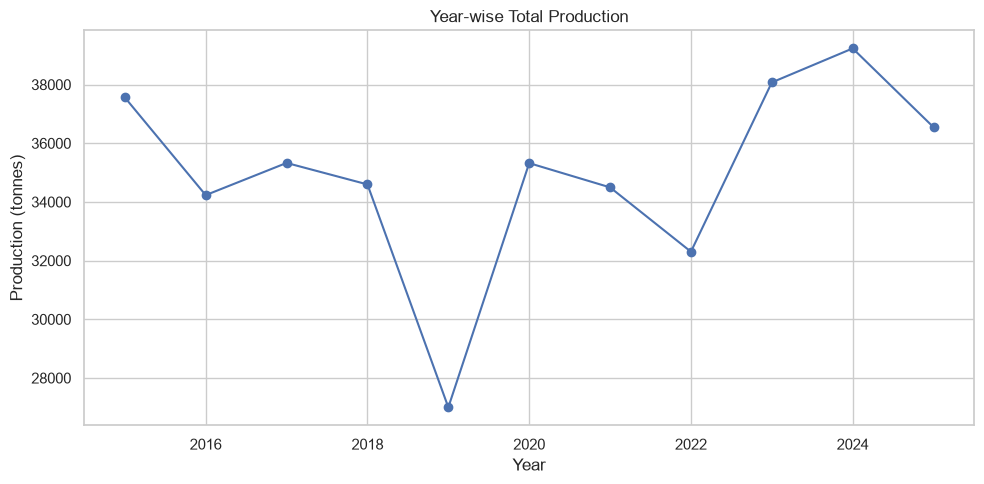

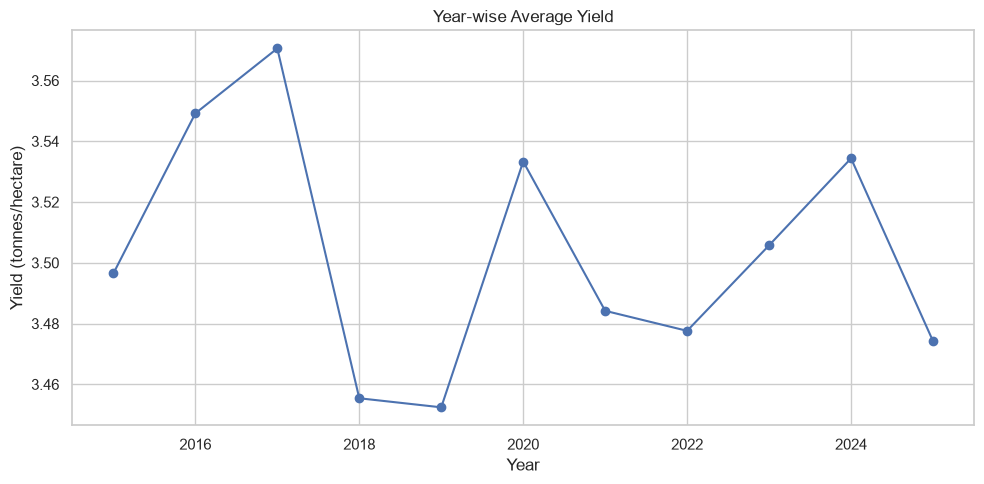

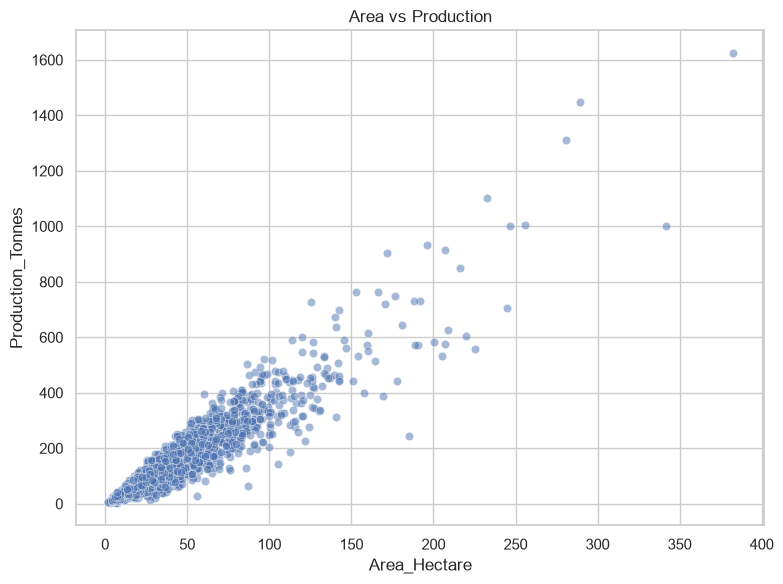

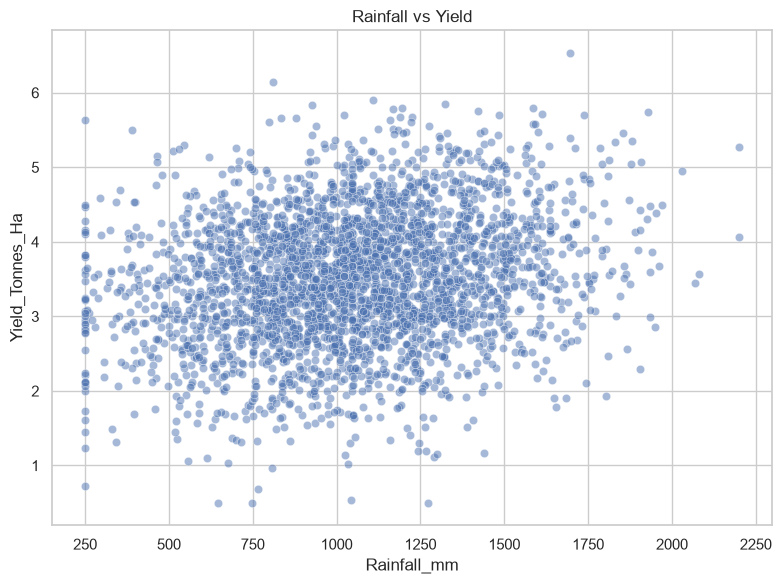

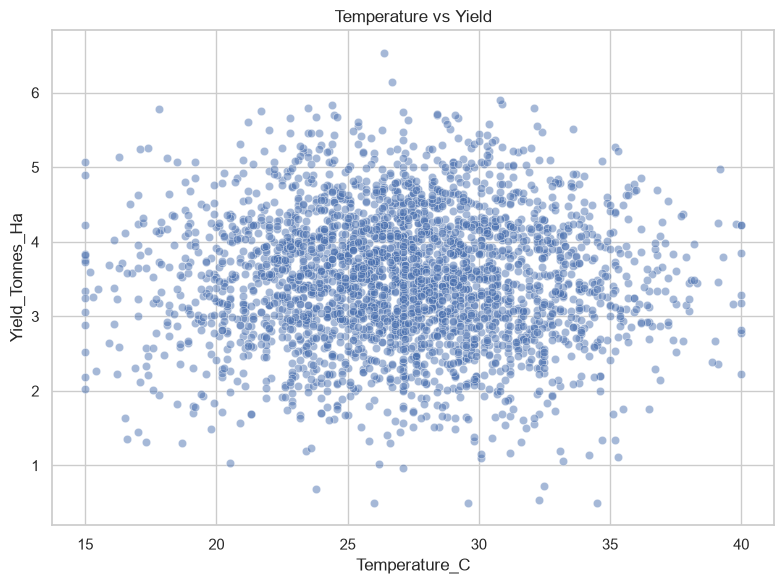

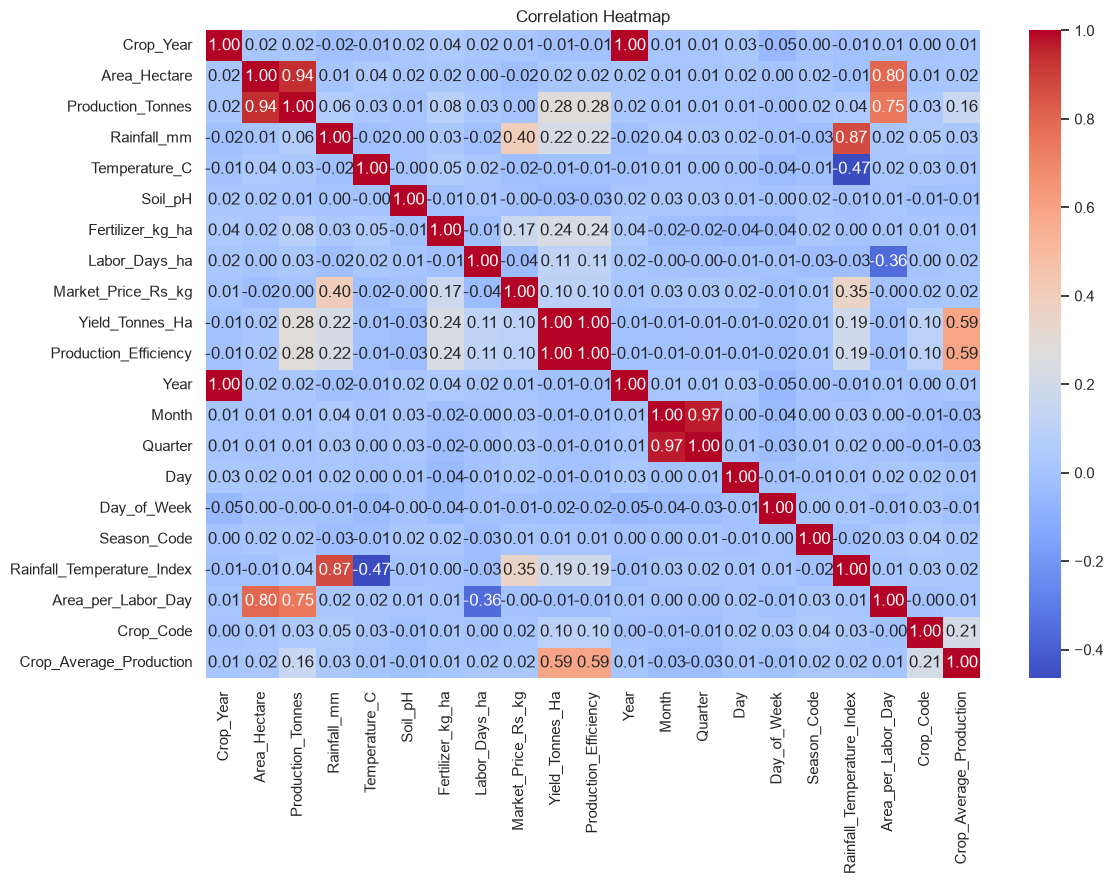

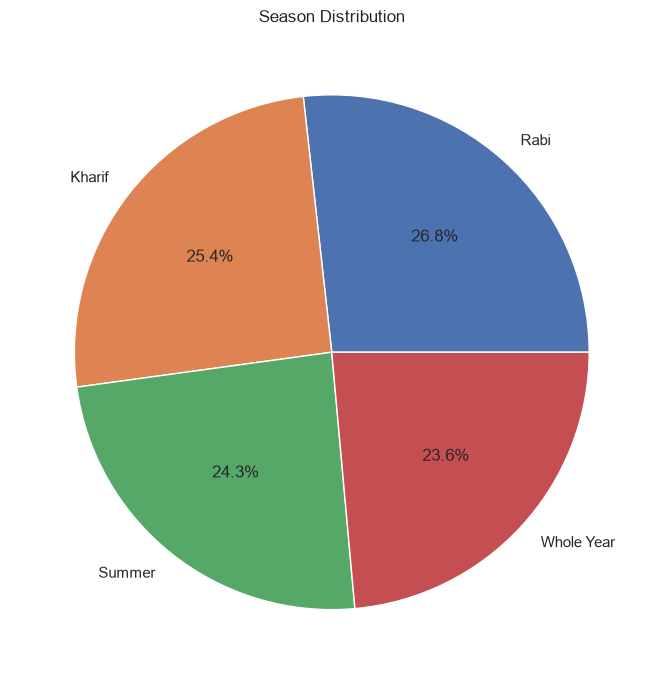

In [18]:
sns.set_theme(style="whitegrid")

# 1. Crop frequency
plt.figure(figsize=(10, 5))
data["Crop"].value_counts().plot(kind="bar")
plt.title("Number of Records by Crop")
plt.xlabel("Crop")
plt.ylabel("Number of Records")
plt.xticks(rotation=35)
plt.tight_layout()
plt.show()

# 2. Production histogram
plt.figure(figsize=(8, 5))
plt.hist(data["Production_Tonnes"], bins=30)
plt.title("Production Distribution")
plt.xlabel("Production (tonnes)")
plt.ylabel("Frequency")
plt.tight_layout()
plt.show()

# 3. Yield histogram
plt.figure(figsize=(8, 5))
plt.hist(data["Yield_Tonnes_Ha"], bins=30)
plt.title("Yield Distribution")
plt.xlabel("Yield (tonnes/hectare)")
plt.ylabel("Frequency")
plt.tight_layout()
plt.show()

# 4. Yield by crop
plt.figure(figsize=(12, 6))
sns.boxplot(data=data, x="Crop", y="Yield_Tonnes_Ha")
plt.title("Yield Distribution by Crop")
plt.xticks(rotation=35)
plt.tight_layout()
plt.show()

# 5. Production by season
plt.figure(figsize=(8, 5))
sns.boxplot(data=data, x="Season", y="Production_Tonnes")
plt.title("Production Distribution by Season")
plt.tight_layout()
plt.show()

# 6. Total production by crop
crop_production = (
    data.groupby("Crop")["Production_Tonnes"]
    .sum()
    .sort_values(ascending=False)
)
plt.figure(figsize=(10, 5))
crop_production.plot(kind="bar")
plt.title("Total Production by Crop")
plt.ylabel("Production (tonnes)")
plt.xticks(rotation=35)
plt.tight_layout()
plt.show()

# 7. Average yield by state
state_yield = (
    data.groupby("State_Name")["Yield_Tonnes_Ha"]
    .mean()
    .sort_values(ascending=False)
)
plt.figure(figsize=(10, 5))
state_yield.plot(kind="bar")
plt.title("Average Yield by State")
plt.ylabel("Yield (tonnes/hectare)")
plt.xticks(rotation=35)
plt.tight_layout()
plt.show()

# 8. Year-wise production
annual_production = (
    data.groupby("Crop_Year")["Production_Tonnes"]
    .sum()
    .sort_index()
)
plt.figure(figsize=(10, 5))
annual_production.plot(marker="o")
plt.title("Year-wise Total Production")
plt.xlabel("Year")
plt.ylabel("Production (tonnes)")
plt.tight_layout()
plt.show()

# 9. Year-wise average yield
annual_yield = (
    data.groupby("Crop_Year")["Yield_Tonnes_Ha"]
    .mean()
    .sort_index()
)
plt.figure(figsize=(10, 5))
annual_yield.plot(marker="o")
plt.title("Year-wise Average Yield")
plt.xlabel("Year")
plt.ylabel("Yield (tonnes/hectare)")
plt.tight_layout()
plt.show()

# 10. Area vs production
plt.figure(figsize=(8, 6))
sns.scatterplot(
    data=data,
    x="Area_Hectare",
    y="Production_Tonnes",
    alpha=0.5
)
plt.title("Area vs Production")
plt.tight_layout()
plt.show()

# 11. Rainfall vs yield
plt.figure(figsize=(8, 6))
sns.scatterplot(
    data=data,
    x="Rainfall_mm",
    y="Yield_Tonnes_Ha",
    alpha=0.5
)
plt.title("Rainfall vs Yield")
plt.tight_layout()
plt.show()

# 12. Temperature vs yield
plt.figure(figsize=(8, 6))
sns.scatterplot(
    data=data,
    x="Temperature_C",
    y="Yield_Tonnes_Ha",
    alpha=0.5
)
plt.title("Temperature vs Yield")
plt.tight_layout()
plt.show()

# 13. Correlation heatmap
plt.figure(figsize=(12, 9))
sns.heatmap(
    data.select_dtypes(include=np.number).corr(),
    annot=True,
    fmt=".2f",
    cmap="coolwarm"
)
plt.title("Correlation Heatmap")
plt.tight_layout()
plt.show()

# 14. Season distribution
plt.figure(figsize=(7, 7))
data["Season"].value_counts().plot(
    kind="pie",
    autopct="%1.1f%%"
)
plt.title("Season Distribution")
plt.ylabel("")
plt.tight_layout()
plt.show()


In [19]:
# Target
target = "Yield_Tonnes_Ha"

features = [
    "Area_Hectare",
    "Rainfall_mm",
    "Temperature_C",
    "Soil_pH",
    "Fertilizer_kg_ha",
    "Labor_Days_ha",
    "Market_Price_Rs_kg"
]

X = data[features].copy()
y = data[target].copy()

print("X shape:", X.shape)
print("y shape:", y.shape)
print(X.head())
print(y.head())
print(X.dtypes)
print(y.dtypes)

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

numeric_features = features

preprocessor = ColumnTransformer(
    transformers=[
        (
            "num",
            Pipeline([
                ("imputer", SimpleImputer(strategy="median")),
                ("scaler", StandardScaler())
            ]),
            numeric_features
        )
    ]
)


X shape: (3000, 7)
y shape: (3000,)
   Area_Hectare  Rainfall_mm  Temperature_C  Soil_pH  Fertilizer_kg_ha  \
0         15.26        769.9           23.4     6.40             195.2   
1         19.18        856.6           27.1     5.21             176.3   
2          5.00        916.4           28.4     7.26             188.6   
3         34.88       1309.0           26.5     7.37             104.0   
4         22.10        989.3           26.1     7.89             110.9   

   Labor_Days_ha  Market_Price_Rs_kg  
0           81.1               31.85  
1           51.8               55.53  
2           60.4               40.04  
3           49.6               34.53  
4           31.8               36.80  
0    2.769332
1    3.494265
2    4.686000
3    3.241399
4    4.712670
Name: Yield_Tonnes_Ha, dtype: float64
Area_Hectare          float64
Rainfall_mm           float64
Temperature_C         float64
Soil_pH               float64
Fertilizer_kg_ha      float64
Labor_Days_ha         float

In [20]:
models = {
    "Linear Regression": LinearRegression(),
    "Decision Tree": DecisionTreeRegressor(
        random_state=42,
        max_depth=10
    ),
    "Random Forest": RandomForestRegressor(
        n_estimators=200,
        random_state=42,
        n_jobs=-1,
        max_depth=15
    )
}

results = []
predictions = {}

for name, model in models.items():
    pipe = Pipeline([
        ("preprocessor", preprocessor),
        ("model", model)
    ])

    pipe.fit(X_train, y_train)
    pred = pipe.predict(X_test)

    predictions[name] = pred

    mae = mean_absolute_error(y_test, pred)
    mse = mean_squared_error(y_test, pred)
    rmse = np.sqrt(mse)
    r2 = r2_score(y_test, pred)

    results.append({
        "Model": name,
        "MAE": mae,
        "MSE": mse,
        "RMSE": rmse,
        "R2": r2
    })

results_df = pd.DataFrame(results).sort_values(
    "RMSE"
)

print(results_df)


               Model       MAE       MSE      RMSE        R2
0  Linear Regression  0.637669  0.636151  0.797591  0.107966
2      Random Forest  0.668020  0.681447  0.825498  0.044450
1      Decision Tree  0.763228  0.941151  0.970129 -0.319717


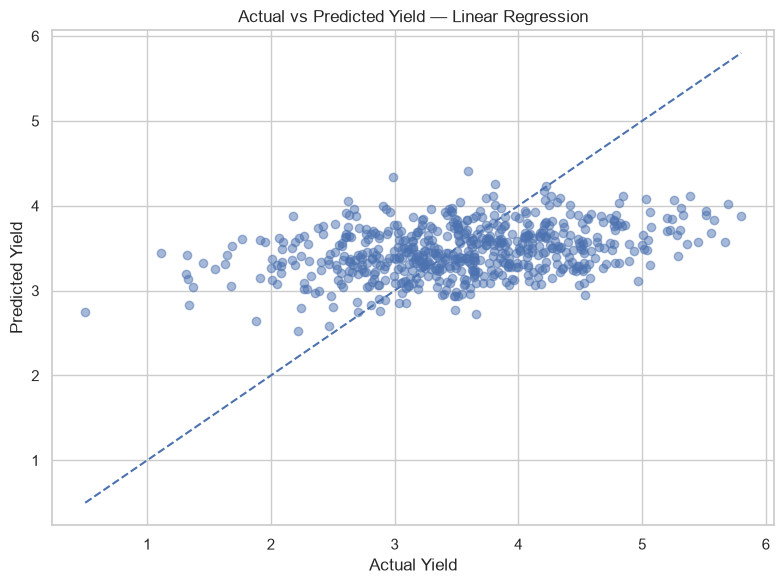

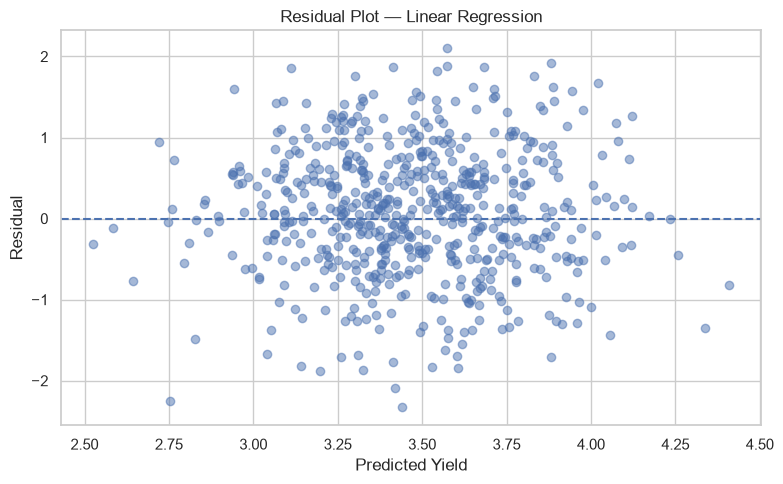

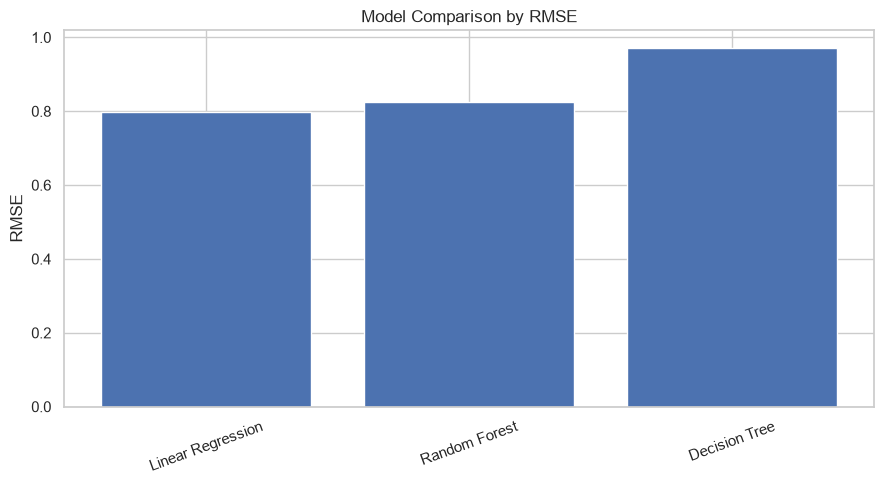

In [21]:
best_model_name = results_df.iloc[0]["Model"]
best_pred = predictions[best_model_name]

# Actual vs predicted
plt.figure(figsize=(8, 6))
plt.scatter(y_test, best_pred, alpha=0.5)
lims = [
    min(y_test.min(), best_pred.min()),
    max(y_test.max(), best_pred.max())
]
plt.plot(lims, lims, linestyle="--")
plt.xlabel("Actual Yield")
plt.ylabel("Predicted Yield")
plt.title(f"Actual vs Predicted Yield — {best_model_name}")
plt.tight_layout()
plt.show()

# Residual plot
residuals = y_test - best_pred

plt.figure(figsize=(8, 5))
plt.scatter(best_pred, residuals, alpha=0.5)
plt.axhline(0, linestyle="--")
plt.xlabel("Predicted Yield")
plt.ylabel("Residual")
plt.title(f"Residual Plot — {best_model_name}")
plt.tight_layout()
plt.show()

# Model comparison
plt.figure(figsize=(9, 5))
plt.bar(results_df["Model"], results_df["RMSE"])
plt.ylabel("RMSE")
plt.title("Model Comparison by RMSE")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()


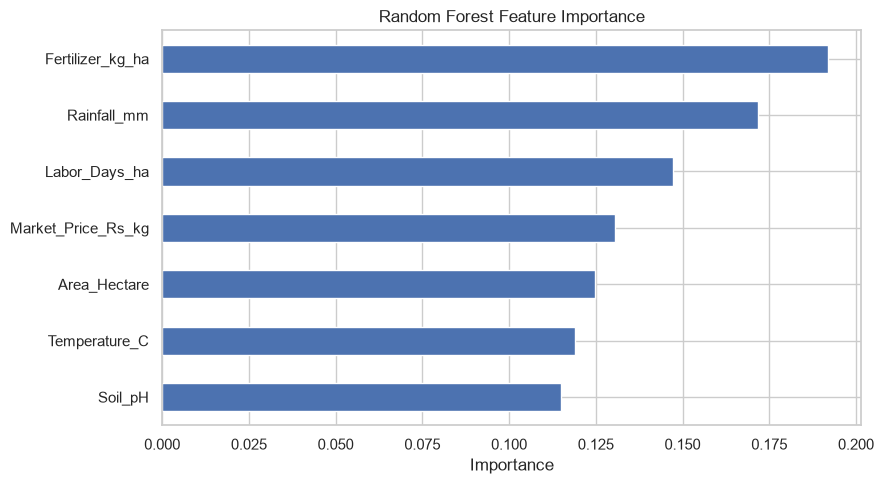

Fertilizer_kg_ha      0.191959
Rainfall_mm           0.171610
Labor_Days_ha         0.147137
Market_Price_Rs_kg    0.130466
Area_Hectare          0.124879
Temperature_C         0.119097
Soil_pH               0.114852
dtype: float64


In [22]:
rf_pipe = Pipeline([
    ("preprocessor", preprocessor),
    ("model", RandomForestRegressor(
        n_estimators=200,
        random_state=42,
        n_jobs=-1,
        max_depth=15
    ))
])

rf_pipe.fit(X_train, y_train)

rf_model = rf_pipe.named_steps["model"]
importance = pd.Series(
    rf_model.feature_importances_,
    index=features
).sort_values(ascending=False)

plt.figure(figsize=(9, 5))
importance.sort_values().plot(kind="barh")
plt.title("Random Forest Feature Importance")
plt.xlabel("Importance")
plt.tight_layout()
plt.show()

print(importance)


In [23]:
final_dataset = data.copy()

final_dataset.to_csv(
    "final_ml_dataset.csv",
    index=False
)

final_dataset.to_excel(
    "final_ml_dataset.xlsx",
    index=False
)

# Verify
check_csv = pd.read_csv("final_ml_dataset.csv")
check_excel = pd.read_excel("final_ml_dataset.xlsx")

print("CSV shape:", check_csv.shape)
print("Excel shape:", check_excel.shape)
print(check_csv.head())


CSV shape: (3000, 29)
Excel shape: (3000, 29)
         Date      State_Name District_Name  Crop_Year      Season       Crop  \
0  2015-01-23  Madhya Pradesh      Jabalpur       2015      Kharif      Maize   
1  2015-01-06   Uttar Pradesh        Kanpur       2015  Whole Year       Rice   
2  2017-01-03       Karnataka      Belagavi       2017      Kharif     Tomato   
3  2019-12-19  Madhya Pradesh      Jabalpur       2019        Rabi     Pulses   
4  2017-10-02     Maharashtra        Nashik       2017      Kharif  Sugarcane   

   Area_Hectare  Production_Tonnes  Rainfall_mm  Temperature_C  ...  Day  \
0         15.26              42.26        769.9           23.4  ...   23   
1         19.18              67.02        856.6           27.1  ...    6   
2          5.00              23.43        916.4           28.4  ...    3   
3         34.88             113.06       1309.0           26.5  ...   19   
4         22.10             104.15        989.3           26.1  ...    2   

   Day_of_